# Day 3: Image Segmentation — Semantic vs Instance

Goal: understand segmentation, compare semantic segmentation (U-Net) with instance segmentation (Mask R-CNN), run a pretrained model, and inspect its mask outputs.

The notebook uses a pretrained Mask R-CNN model from `torchvision` and a sample COCO image. The model weights and image download automatically.

Setup and imports

In [1]:
import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


What is image segmentation?

Image segmentation assigns labels to pixels or regions.

- **Object detection** predicts bounding boxes around objects.
- **Segmentation** predicts pixel-level regions, giving a more detailed outline than a box.

**Semantic segmentation** assigns a class to every pixel. All objects of the same class share one label; separate objects are not distinguished.

**Instance segmentation** detects each object separately and predicts a separate mask for each instance. Two people receive separate masks.

U-Net vs Mask R-CNN

**U-Net — commonly used for semantic segmentation**
- Encoder-decoder architecture.
- The encoder captures context; the decoder restores spatial detail.
- Skip connections transfer fine-grained features from encoder stages to decoder stages.
- Often used in medical imaging and other pixel-level classification tasks.

**Mask R-CNN — instance segmentation**
- Extends the Faster R-CNN object detector.
- Predicts object classes and bounding boxes, and adds a branch that predicts a mask for each detected instance.
- Useful when separate objects of the same class must be distinguished.

The key distinction is the output: U-Net commonly produces a class map for the whole image, while Mask R-CNN produces separate masks for detected objects.

Load a sample image

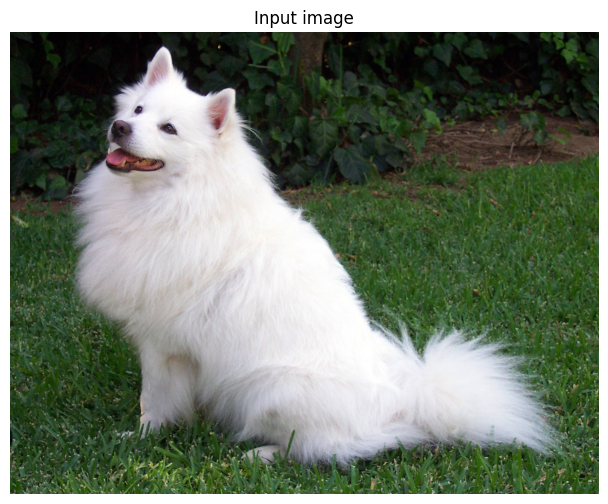

Image size: (1546, 1213)


In [4]:
# This COCO sample image contains a dog
image_url = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"

response = requests.get(image_url, timeout=30)
response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")

plt.figure(figsize=(9, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Input image")
plt.show()

print("Image size:", image.size)

Load pretrained Mask R-CNN

In [5]:
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
model = maskrcnn_resnet50_fpn(weights=weights).to(device)
model.eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]
print("Pretrained Mask R-CNN loaded.")
print("Number of COCO categories:", len(categories))

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 98.4MB/s]


Pretrained Mask R-CNN loaded.
Number of COCO categories: 91


Run instance segmentation

In [6]:
image_tensor = preprocess(image).to(device)
with torch.no_grad():
    prediction = model([image_tensor])[0]

print("Output keys:", prediction.keys())
print("Number of detected instances:", len(prediction["boxes"]))
print("Boxes shape:", prediction["boxes"].shape)
print("Labels shape:", prediction["labels"].shape)
print("Scores shape:", prediction["scores"].shape)
print("Masks shape:", prediction["masks"].shape)

Output keys: dict_keys(['boxes', 'labels', 'scores', 'masks'])
Number of detected instances: 3
Boxes shape: torch.Size([3, 4])
Labels shape: torch.Size([3])
Scores shape: torch.Size([3])
Masks shape: torch.Size([3, 1, 1213, 1546])


Understand the mask output

For Mask R-CNN, `prediction["masks"]` has shape `[number_of_detections, 1, image_height, image_width]`.

Each detected instance has its own mask. Values are probabilities between 0 and 1. We apply a threshold (0.5 here) to convert each probability mask into a binary mask:

- 1 / True: pixel belongs to this detected instance.
- 0 / False: pixel does not belong to this instance.

The model also returns:
- `boxes`: bounding boxes in `(x1, y1, x2, y2)` format.
- `labels`: predicted COCO class IDs.
- `scores`: confidence scores.

Display predicted instances

/tmp/ipykernel_1431/3734092675.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", max(len(filtered_indices), 1))


Instances above confidence threshold: 1


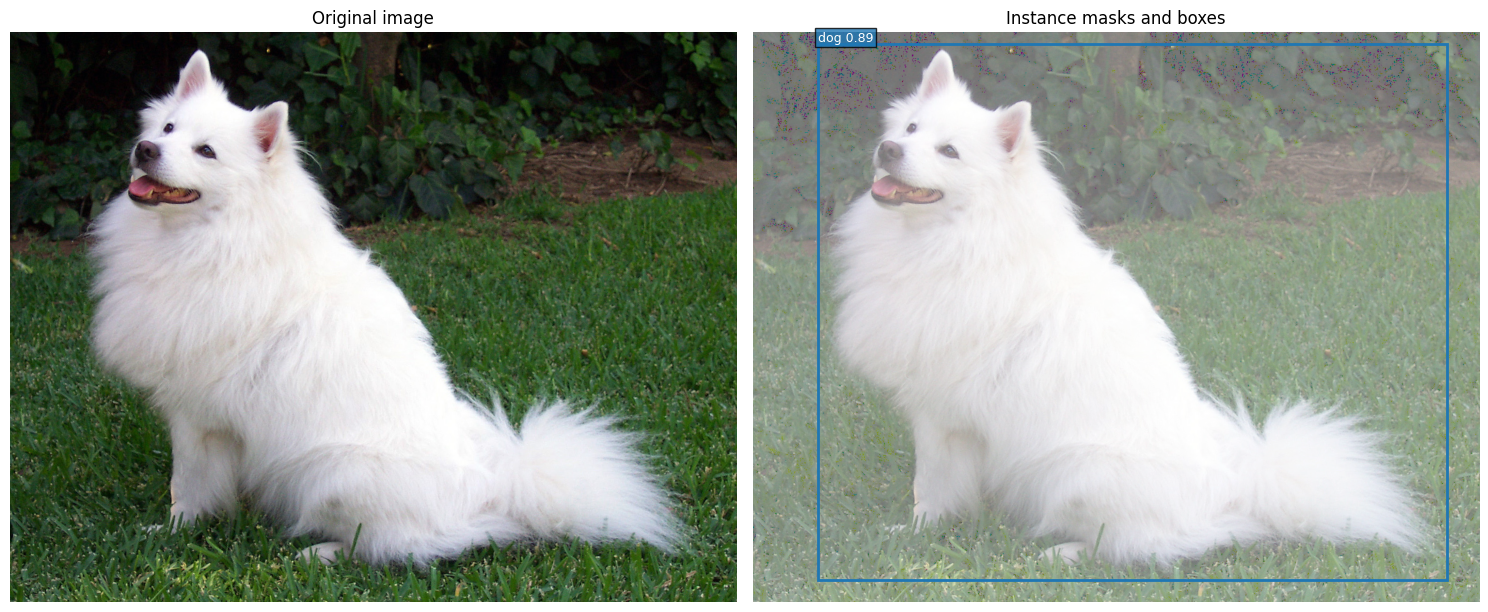

In [7]:
score_threshold = 0.70
mask_threshold = 0.50
image_array = np.array(image)
keep = prediction["scores"].detach().cpu().numpy() >= score_threshold
filtered_indices = np.where(keep)[0]
print("Instances above confidence threshold:", len(filtered_indices))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].imshow(image_array)
axes[0].set_title("Original image")
axes[0].axis("off")
axes[1].imshow(image_array)
axes[1].set_title("Instance masks and boxes")
axes[1].axis("off")

colors = plt.cm.get_cmap("tab10", max(len(filtered_indices), 1))
for display_index, detection_index in enumerate(filtered_indices):
    score = float(prediction["scores"][detection_index].cpu())
    class_id = int(prediction["labels"][detection_index].cpu())
    class_name = categories[class_id]
    mask = prediction["masks"][detection_index, 0].detach().cpu().numpy()
    binary_mask = mask >= mask_threshold
    color = colors(display_index)[:3]

    overlay = np.zeros_like(image_array, dtype=np.float32)
    overlay[binary_mask] = np.array(color) * 255
    axes[1].imshow(np.where(binary_mask[..., None], overlay, image_array), alpha=0.45)

    x1, y1, x2, y2 = prediction["boxes"][detection_index].detach().cpu().numpy()
    rectangle = plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2)
    axes[1].add_patch(rectangle)
    axes[1].text(x1, max(0, y1-5), f"{class_name} {score:.2f}",
                 color="white", fontsize=9,
                 bbox=dict(facecolor=color, alpha=0.8, pad=2))

plt.tight_layout()
plt.show()

Inspect one mask as a grayscale image

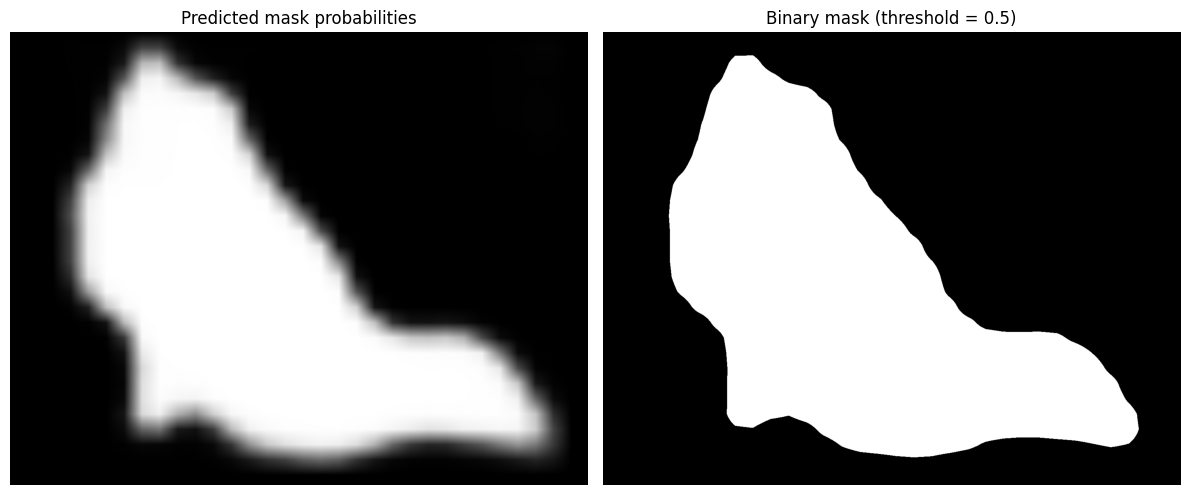

In [8]:
if len(filtered_indices) > 0:
    first_index = int(filtered_indices[0])
    first_mask = prediction["masks"][first_index, 0].detach().cpu().numpy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(first_mask, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Predicted mask probabilities")
    axes[0].axis("off")
    axes[1].imshow(first_mask >= mask_threshold, cmap="gray")
    axes[1].set_title("Binary mask (threshold = 0.5)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No detections passed the confidence threshold. Try lowering score_threshold.")

Create a table of detections

In [9]:
import pandas as pd
detection_rows = []
for index in filtered_indices:
    class_id = int(prediction["labels"][index].cpu())
    x1, y1, x2, y2 = prediction["boxes"][index].detach().cpu().tolist()
    detection_rows.append({
        "class": categories[class_id],
        "confidence": round(float(prediction["scores"][index].cpu()), 3),
        "x1": round(x1, 1), "y1": round(y1, 1),
        "x2": round(x2, 1), "y2": round(y2, 1)
    })
detections_df = pd.DataFrame(detection_rows)
display(detections_df)

,class,confidence,x1,y1,x2,y2
0,dog,0.893,138.2,24.1,1477.3,1165.6
